## PageRank y HITS: Análisis

- Se contrasta la centralidad con el monto, con las tipologías de KMeans y con la cautividad

- Se responde la parte de PQ1 que toca a los actores centrales; local (pandas)

### Constantes

- `RANGO_P_ALTO`: percentiles para llamar "muy central" a un actor

In [1]:
RANGO_P_ALTO = [0.95, 0.99, 0.999]

### Utilidades

In [2]:
%cd /home/jovyan/work/04_PAGERANKHITS

/home/jovyan/work/04_PAGERANKHITS


In [6]:
NOTEBOOK = "d_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

In [4]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [7]:
config = leer_config()
n_e = config["n_e"]
tabla = lambda nb, t: pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / t)

v = (pd.read_parquet(datos_dir / "nodos.parquet")
       .merge(pd.read_parquet(datos_dir / "pagerank.parquet")[["idx", "pr"]], on="idx")
       .merge(pd.read_parquet(datos_dir / "hits.parquet"), on="idx"))
for c in ("pr", "hits", "grado", "fuerza", "monto"):
    v[f"pct_{c}"] = pct_por_tipo(v, c)
a = pd.read_parquet(datos_dir / "aristas.parquet")

fe = pd.read_parquet(artef_dir / "features_entidad",
                     columns=["entidad_key", "n_procesos", "hhi_proveedores", "share_top_proveedores", "pct_postor_unico", "pct_directa"])
fp = pd.read_parquet(artef_dir / "features_proveedor", columns=["proveedor_key", "n_procesos", "n_entidades", "hhi_entidades"])
ent = (v[v.tipo == "entidad"].merge(fe, left_on="clave", right_on="entidad_key", how="left")
         .merge(tipologia("entidad", "entidad_key"), on="entidad_key", how="left"))
prov = (v[v.tipo == "proveedor"].merge(fp, left_on="clave", right_on="proveedor_key", how="left")
          .merge(tipologia("proveedor", "proveedor_key"), on="proveedor_key", how="left"))
ent["tipologia"] = ent.tipologia.fillna("fuera del clustering (< 5 procesos)")
prov["tipologia"] = prov.tipologia.fillna("esporádico (fuera del clustering)")
prov["hits_rel"] = prov.hits / prov.hits.max()
print(f"entidades: {len(ent):,} | proveedores: {len(prov):,}")

entidades: 2,992 | proveedores: 86,038


---
### **1. Qué mide cada medida**

In [8]:
medidas = {"entidad": ["grado", "fuerza", "monto", "pr", "hits"],
           "proveedor": ["grado", "fuerza", "monto", "cuota_billetera", "pr", "hits"]}
corr = pd.concat({s: d[medidas[s]].corr(method="spearman").round(2) for s, d in (("entidad", ent), ("proveedor", prov))})
corr

grado  fuerza  monto    pr  hits  cuota_billetera
entidad   grado             1.00    0.99   0.87  0.98  0.72              NaN
          fuerza            0.99    1.00   0.85  0.97  0.74              NaN
          monto             0.87    0.85   1.00  0.88  0.55              NaN
          pr                0.98    0.97   0.88  1.00  0.60              NaN
          hits              0.72    0.74   0.55  0.60  1.00              NaN
proveedor grado             1.00    0.79   0.31  0.56  0.39             0.41
          fuerza            0.79    1.00   0.28  0.70  0.46             0.33
          monto             0.31    0.28   1.00  0.26  0.10             0.19
          cuota_billetera   0.41    0.33   0.19  0.48 -0.40             1.00
          pr                0.56    0.70   0.26  1.00 -0.14             0.48
          hits              0.39    0.46   0.10 -0.14  1.00            -0.40

- **PageRank ≈ fuerza** (Spearman **XX**): con d = 0.85 en un no dirigido, la recursión corrige al volumen pero no lo reemplaza

- **PageRank vs monto** es más débil (**XX**): por diseño, el peso es `n_adj`

- **HITS** se separa de todo fuera del núcleo (muchos ceros): es la medida menos redundante

- **`cuota_billetera`** (el PageRank dirigido) mide otra cosa: dependencia de los compradores

---
### **2. Centralidad vs monto**

Ajuste log PageRank ~ log monto en proveedores; el residuo dice quién es más (o menos) central de lo que su monto predice

In [9]:
p_ = prov[prov.monto > 0].copy()
x, y = np.log10(p_.monto), np.log10(p_.pr)
b1, b0 = np.polyfit(x, y, 1)
p_["residuo"] = y - (b0 + b1 * x)
print(f"pendiente = {b1:.2f} | R² = {np.corrcoef(x, y)[0, 1] ** 2:.2f}")

cols = ["nombre", "tipologia", "es_consorcio", "grado", "fuerza", "monto", "pct_pr", "pct_hits", "residuo"]
mas_central, mas_monto = p_.nlargest(10, "residuo")[cols], p_.nsmallest(10, "residuo")[cols]
grupo = np.select([p_.residuo >= p_.residuo.quantile(P_ALTO), p_.residuo <= p_.residuo.quantile(1 - P_ALTO)],
                  ["más central que su monto", "más monto que centralidad"], "resto")
contraste = (p_.assign(grupo=grupo).groupby("grupo")
               .agg(proveedores=("idx", "size"), pct_consorcio=("es_consorcio", lambda s: 100 * s.fillna(0).mean()),
                    grado_med=("grado", "median"), monto_med=("monto", "median"), entidades_med=("n_entidades", "median"))
               .round(1))
display(contraste); display(mas_central); display(mas_monto)

pendiente = 0.10 | R² = 0.12


,proveedores,pct_consorcio,grado_med,monto_med,entidades_med
grupo,,,,,
más central que su monto,861,0.6,17.0,9327101.6,17.0
más monto que centralidad,861,82.7,1.0,21479010.6,1.0
resto,84295,49.7,1.0,290486.5,1.0


,nombre,tipologia,es_consorcio,grado,fuerza,monto,pct_pr,pct_hits,residuo
65816,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,0.0,275,1704.0,3.555030e+08,1.000000,0.998373,2.416561
67603,AGROINDUSTRIA LA PERLA DEL HUASCARAN S.R.L.,grandes multicliente,0.0,68,179.0,3.130010e+07,0.999954,0.813780,1.873698
69103,TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.,grandes multicliente,0.0,160,325.0,5.076491e+07,0.999965,0.975395,1.862936
65227,DIAGNOSTICA PERUANA S.A.C.,grandes multicliente,0.0,109,572.0,4.083834e+08,0.999988,1.000000,1.818071
62039,MAPFRE PERU COMPAÑIA DE SEGUROS Y REASEGUROS,grandes multicliente,0.0,177,344.0,5.986473e+08,0.999977,0.998466,1.752521
63209,AMERICA MOVIL PERU S.A.C.,grandes multicliente,0.0,177,334.0,5.419096e+08,0.999942,0.994700,1.740285
59905,FERREYROS SOCIEDAD ANÓNIMA,grandes multicliente,0.0,171,236.0,5.844381e+08,0.999930,0.970966,1.700408
62638,COMERCIAL FERRETERIA FATIMA SOCIEDAD ANONIMA CERRADA - COMERCIAL FERRETERIA ...,grandes multicliente,0.0,73,268.0,4.498869e+07,0.999884,0.990795,1.694888
59904,UNIMAQ S.A.,grandes multicliente,0.0,166,209.0,2.048934e+08,0.999907,0.971292,1.681899
63616,CORPORACION DE LOS ANDES E.I.R.L.,grandes multicliente,0.0,78,128.0,2.348107e+07,0.999849,0.804052,1.668649


,nombre,tipologia,es_consorcio,grado,fuerza,monto,pct_pr,pct_hits,residuo
16623,CONSORCIO EDIFICADOR SUR,esporádico (fuera del clustering),1.0,1,1.0,3.478837e+08,0.015150,0.980828,-0.543305
3616,CONSORCIO CRETA,esporádico (fuera del clustering),1.0,1,1.0,1.857265e+08,0.015150,0.980828,-0.515177
33898,FABRICA DE ARMAS Y MUNICIONES DEL EJERCITO SAC - FAME SAC,esporádico (fuera del clustering),1.0,1,1.0,2.020042e+08,0.026785,0.952713,-0.505513
18258,CONSORCIO DEPORTIVO LIBERTAD,esporádico (fuera del clustering),1.0,1,1.0,3.808395e+08,0.072700,0.823287,-0.504814
69725,J Y S SERVICIOS GENERALES SOCIEDAD ANONIMA CERRADA ¿ J Y S SERVICIOS GENERAL...,esporádico (fuera del clustering),0.0,1,1.0,1.111909e+09,0.241422,0.461000,-0.493773
5245,CONSORCIO SALUD DEL CENTRO,esporádico (fuera del clustering),1.0,1,1.0,2.946966e+08,0.072700,0.823287,-0.493321
20328,CONSORCIO HOSPITALARIO JULI,esporádico (fuera del clustering),1.0,1,1.0,2.028161e+08,0.038303,0.919890,-0.491772
44935,GECI ESPAÑOLA AEROSPACE SOLUTIONS SA,esporádico (fuera del clustering),0.0,1,1.0,1.725570e+08,0.033979,0.931920,-0.487627
26041,CONSORCIO QS CONSUMO S.A.C.-ASTRAZENECA PERU S.A.,esporádico (fuera del clustering),1.0,1,1.0,3.684090e+07,0.000674,0.973942,-0.487173
43679,CANADIAN COMMERCIAL CORPORATION-CCC,esporádico (fuera del clustering),0.0,1,1.0,1.680158e+08,0.033979,0.931920,-0.486431


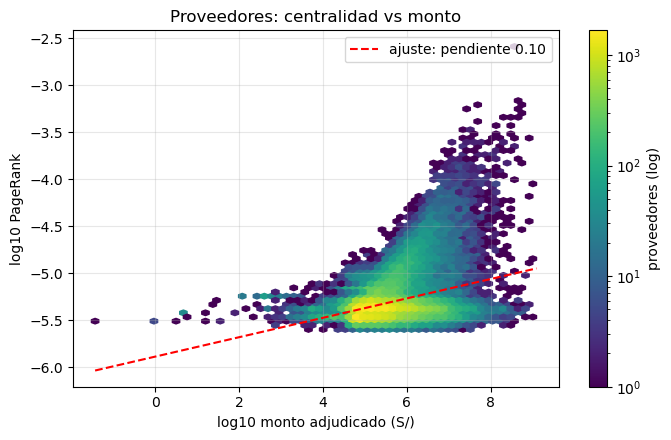

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
hb = ax.hexbin(x, y, gridsize=60, bins="log", cmap="viridis")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, b0 + b1 * xs, "r--", label=f"ajuste: pendiente {b1:.2f}")
ax.set(xlabel="log10 monto adjudicado (S/)", ylabel="log10 PageRank", title="Proveedores: centralidad vs monto"); ax.legend()
plt.colorbar(hb, ax=ax, label="proveedores (log)")
mostrar_fig("pagerank_vs_monto")

- **Pendiente XX, R² XX:** el monto explica solo parte de la centralidad

- **"Más central que su monto"** (top 1% del residuo): muchas adjudicaciones chicas y recurrentes a varias entidades; **XX%** consorcios

- **"Más monto que centralidad"**: casi todos **consorcios** (**XX%**) con una adjudicación grande a una sola entidad (mediana de **XX** entidades)

- Es la **misma población** que en `02_Clustering` atendía a las entidades cautivas: mucho dinero en una arista aislada

---
### **3. Centralidad por tipología (KMeans)**

In [11]:
def por_tipologia(d):
    return (d.groupby("tipologia")
             .agg(actores=("idx", "size"), pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                  en_top_pr=("pct_pr", lambda s: int((s >= P_ALTO).sum())), en_top_hits=("pct_hits", lambda s: int((s >= P_ALTO).sum())))
             .round(3))

tip_ent, tip_prov = por_tipologia(ent), por_tipologia(prov)
display(tip_ent); display(tip_prov)

,actores,pct_pr_med,pct_hits_med,en_top_pr,en_top_hits
tipologia,,,,,
compra sin competencia,873,0.827,0.786,24,26
compradoras de obras,235,0.654,0.693,6,4
compradoras pequeñas,905,0.327,0.462,0,0
fuera del clustering (< 5 procesos),296,0.066,0.098,0,0
grandes diversificadas,683,0.481,0.296,0,0


,actores,pct_pr_med,pct_hits_med,en_top_pr,en_top_hits
tipologia,,,,,
contratistas de obras,807,0.933,0.717,10,24
esporádico (fuera del clustering),72719,0.423,0.439,0,76
ganadores sin competencia,1048,0.905,0.852,22,42
grandes multicliente,3019,0.979,0.931,810,472
típicos de pocos clientes,8445,0.901,0.828,19,247


- **Proveedores:** los **grandes multicliente** concentran **XX** de los **XX** del top 1% de PageRank y **XX** del de HITS

- **"Ganadores sin competencia"** (Lima, personas naturales) quedan en percentil mediano **XX**: ganan seguido, pero a pocas entidades

- **Esporádicos** (fuera del clustering): HITS ≈ 0, PageRank mediano **XX**

- **Entidades:** las **grandes diversificadas** son los hubs (**XX** del top 1%); las **compradoras pequeñas** y **de obras**, las de menor centralidad

- **Convergencia con la Parte II:** centralidad y tipologías cuentan la misma historia; la novedad está en los que no encajan (§2)

---
### **4. Cautividad y centralidad (PQ1)**

- Mismo filtro (`n_procesos ≥ 5`) y umbral (`HHI ≥ 0.25`) que `02_Clustering`

- **Proveedor principal** de cada entidad: el de mayor monto

In [12]:
e5 = ent[ent.n_procesos >= MIN_PROC_ENT].copy()
e5["cautiva"] = (e5.hhi_proveedores >= UMBRAL_HHI).astype(int)
cautividad = (e5.groupby("cautiva").agg(entidades=("idx", "size"), pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                                        grado_med=("grado", "median"), pct_en_gigante=("en_gigante", lambda s: 100 * s.mean()))
                .round(3))

top = (a.assign(monto=a.monto.fillna(0)).sort_values("monto", ascending=False).drop_duplicates("i")
        .rename(columns={"i": "idx_e", "monto": "monto_rel"}))
top["idx"] = top.j + n_e
principal = (e5[["idx", "cautiva"]].rename(columns={"idx": "idx_e"}).merge(top[["idx_e", "idx", "monto_rel"]], on="idx_e")
               .merge(prov[["idx", "nombre", "tipologia", "es_consorcio", "pct_pr", "pct_hits", "hits_rel", "cuota_billetera"]], on="idx"))
atiende = (principal.groupby("cautiva")
             .agg(entidades=("idx_e", "size"), pct_consorcio=("es_consorcio", lambda s: 100 * s.fillna(0).mean()),
                  pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                  pct_hits_cero=("hits_rel", lambda s: 100 * (s < 1e-6).mean()), cuota_med=("cuota_billetera", "median"))
             .round(3))
display(cautividad); display(atiende)

,entidades,pct_pr_med,pct_hits_med,grado_med,pct_en_gigante
cautiva,,,,,
0,1889,0.674,0.647,35.0,99.100
1,807,0.293,0.330,8.0,92.689


,entidades,pct_consorcio,pct_pr_med,pct_hits_med,pct_hits_cero,cuota_med
cautiva,,,,,,
0,1889,50.821,0.733,0.450,44.256,0.058
1,807,67.286,0.730,0.142,73.234,0.125


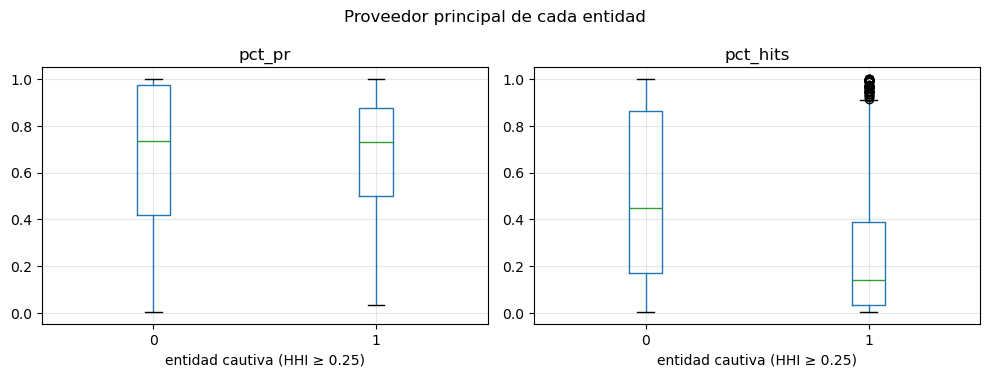

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k_, c in enumerate(("pct_pr", "pct_hits")):
    principal.boxplot(column=c, by="cautiva", ax=ax[k_])
    ax[k_].set(title=c, xlabel="entidad cautiva (HHI ≥ 0.25)")
plt.suptitle("Proveedor principal de cada entidad")
mostrar_fig("proveedor_principal_cautivas")

- **Las cautivas son periféricas:** hub mediano en percentil **XX** vs **XX** de las no cautivas, y **XX%** fuera de la componente gigante

- **Su proveedor principal no es del núcleo:**
  - El **XX%** tiene authority ≈ 0
  - El **XX%** es consorcio
  - Su PageRank (percentil **XX**) viene de **concentrar la compra de esa entidad**, no de vender a muchas

- **Respuesta a PQ1 (actores centrales):** la concentración del gasto en pocos proveedores **no** es dependencia de los proveedores centrales
  - Los centrales (HITS y PageRank alto) son los grandes multicliente que venden a entidades diversificadas
  - La cautividad es un fenómeno **local**: entidades chicas o de obras atadas a un proveedor (casi siempre consorcio) que no aparece en el resto de la red

---
### **5. Variación de los resultados**

In [14]:
variacion = pd.concat([
    tabla("a_grafo", "eleccion_peso").assign(parametro="peso (PageRank)", valor=lambda t: t.peso,
                                             resultado=lambda t: "Spearman con monto " + t.spearman_monto.round(2).astype(str)),
    tabla("b_pagerank", "sensibilidad_damping").query("tipo == 'proveedor'").assign(
        parametro="damping d", valor=lambda t: t.d.astype(str),
        resultado=lambda t: "Spearman vs 0.85 " + t.spearman_vs_085.round(3).astype(str) + ", top-20 " + t.top20_vs_085.round(2).astype(str)),
    pd.DataFrame([{"parametro": "percentil 'alto'", "valor": str(q),
                   "resultado": f"{int(((prov.pct_pr >= q) & (prov.pct_hits < q)).sum())} solo PageRank alto, "
                                f"{int(((prov.pct_pr < q) & (prov.pct_hits >= q)).sum())} solo HITS alto"} for q in RANGO_P_ALTO])
])[["parametro", "valor", "resultado"]]
variacion

,parametro,valor,resultado
0,peso (PageRank),binario,Spearman con monto 0.2
1,peso (PageRank),n_adj,Spearman con monto 0.26
2,peso (PageRank),log_monto,Spearman con monto 0.51
3,peso (PageRank),monto,Spearman con monto 0.86
1,damping d,0.5,"Spearman vs 0.85 0.987, top-20 0.9"
3,damping d,0.65,"Spearman vs 0.85 0.993, top-20 1.0"
5,damping d,0.75,"Spearman vs 0.85 0.997, top-20 1.0"
7,damping d,0.85,"Spearman vs 0.85 1.0, top-20 1.0"
9,damping d,0.9,"Spearman vs 0.85 0.998, top-20 0.9"
11,damping d,0.95,"Spearman vs 0.85 0.99, top-20 0.82"


- **Peso:** `monto` vuelve a PageRank un ranking de monto; `n_adj` y `log_monto` dan rankings parecidos

- **Damping:** estable entre 0.75 y 0.90; las conclusiones no dependen de d = 0.85

- **Percentil alto:** el número de divergentes cambia, pero su perfil (consorcios y locales vs. núcleo nacional) se mantiene

---
### **6. Casos concretos**

In [15]:
casos = pd.concat([
    prov.nlargest(1, "pr").assign(caso="proveedor de mayor PageRank"),
    prov.nlargest(1, "hits").assign(caso="authority principal"),
    p_.nlargest(1, "residuo").assign(caso="proveedor más central que su monto"),
    p_.nsmallest(1, "residuo").assign(caso="proveedor con más monto que centralidad"),
    ent.nlargest(1, "hits").assign(caso="hub principal"),
    e5[e5.cautiva == 1].nlargest(1, "pr").assign(caso="entidad cautiva más central")])
casos = casos[["caso", "nombre", "tipologia", "grado", "fuerza", "monto", "pct_pr", "pct_hits"]]
casos

,caso,nombre,tipologia,grado,fuerza,monto,pct_pr,pct_hits
65816,proveedor de mayor PageRank,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,275,1704.0,3.555030e+08,1.000000,0.998373
65227,authority principal,DIAGNOSTICA PERUANA S.A.C.,grandes multicliente,109,572.0,4.083834e+08,0.999988,1.000000
65816,proveedor más central que su monto,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,275,1704.0,3.555030e+08,1.000000,0.998373
16623,proveedor con más monto que centralidad,CONSORCIO EDIFICADOR SUR,esporádico (fuera del clustering),1,1.0,3.478837e+08,0.015150,0.980828
2190,hub principal,SEGURO SOCIAL DE SALUD,compra sin competencia,1918,5059.0,7.503673e+09,0.999666,1.000000
1246,entidad cautiva más central,MUNICIPALIDAD DISTRITAL DE ILABAYA,compra sin competencia,205,347.0,4.610573e+08,0.964238,0.948864


- **XX** (mayor PageRank): **XX** entidades, **XX** adjudicaciones

- **XX** (authority principal): …

- **XX** (más monto que centralidad): consorcio con S/**XX** en una sola adjudicación

- **XX** (hub principal): …

---
### **7. Limitaciones y ética**

- **Señal, no acusación:** una centralidad alta o una dependencia fuerte describen la forma de la red, no una irregularidad; un proveedor único puede tener exclusividad técnica o geográfica legítima

- **Consorcios sin miembros:** la fuente no publica quién los integra; un grupo empresarial repartido en varios consorcios aparece como muchos nodos periféricos, y su centralidad real queda **subestimada**

- **Proveedores sin región propia:** se ubican por la región de sus clientes

- **La arista es la adjudicación**, no el pago: el 10.8% sin contrato vinculado sigue contando

- **Uso responsable:** los listados con nombres se publican como **perfiles para revisión** por los órganos de control, con la metodología al lado, nunca como ranking de sospechosos

---
### **8. Síntesis**

- **Grafo:** bipartito no dirigido entidad ↔ proveedor con peso `n_adj`; el dirigido E→P degenera en una suma de cuotas de billetera, que se conserva como medida de dependencia

- **PageRank** (Spark validado contra scipy y GraphFrames): estable para d entre 0.75 y 0.90; con d → 1 se vuelve la fuerza

- **HITS** (= SVD de rango 1): se concentra en el núcleo denso y es la medida que más se separa del volumen

- **Actores centrales:** los grandes multicliente y las grandes compradoras diversificadas, igual que las tipologías de KMeans

- **PQ1:** las entidades cautivas son periféricas y dependen de proveedores fuera del núcleo (sobre todo consorcios de un solo proceso); la concentración es **local**, no captura por los proveedores centrales

- **Aporte propio de esta parte:** el contraste centralidad vs monto aísla dos perfiles que el clustering mezcla
  - Proveedores recurrentes de bajo monto, con muchos clientes
  - Consorcios de alto monto con un solo cliente

---
### **9. Escritura de resultados**

In [16]:
web_scatter = p_.nlargest(3000, "fuerza")[["clave", "nombre", "tipologia", "es_consorcio", "grado", "monto",
                                           "pr", "hits", "pct_pr", "pct_hits", "residuo"]]
escritos = guardar_tablas({
    "correlaciones": corr.reset_index().rename(columns={"level_0": "sujeto", "level_1": "medida"}),
    "contraste_monto": contraste.reset_index(), "mas_central_que_monto": mas_central, "mas_monto_que_central": mas_monto,
    "por_tipologia": pd.concat({"entidad": tip_ent, "proveedor": tip_prov}).reset_index().rename(columns={"level_0": "sujeto"}),
    "cautividad": cautividad.reset_index(), "atienden_cautivas": atiende.reset_index(), "variacion": variacion,
    "casos": casos, "centralidad_web": web_scatter})

Escrito en 04_PAGERANKHITS/temp/d_analisis/: correlaciones, contraste_monto, mas_central_que_monto, mas_monto_que_central, por_tipologia, cautividad, atienden_cautivas, variacion, casos, centralidad_web


#### a. Verificación

In [17]:
verificar_salidas(escritos)

OK: 10 tablas (parquet + json) | 2 figuras: pagerank_vs_monto, proveedor_principal_cautivas


---
### **10. Cerrar sesión**

In [18]:
spark.stop()